PHASE 9 : VERIFICATION

In [ ]:
import parquet
import pandas as pd
import json




In [1]:
import pandas as pd
import json
import joblib
import sys
sys.path.append("../src")
from woe import calc_psi, interpret_psi

# --- Charger les scores + cible ---
train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# --- Load scaling parameters ---
with open("../models/scaling_params.json") as f:
    scaling_params = json.load(f)

Factor = scaling_params["Factor"]
Offset = scaling_params["Offset"]
intercept = scaling_params["intercept"]
PDO = scaling_params["PDO"]

# --- Load the scorecard (if needed) ---
scorecard = joblib.load("../models/scorecard.pkl")

# --- Consistency checks ---
assert "score" in train_df.columns, "Colonne 'score' manquante dans train"
assert "default" in train_df.columns, "Colonne 'default' manquante dans train"
assert "score" in test_df.columns, "Colonne 'score' manquante dans test"
assert "default" in test_df.columns, "Colonne 'default' manquante dans test"
assert not train_df.isna().any().any(), "NaN dans train"
assert not test_df.isna().any().any(), "NaN dans test"

print(f"Train : {train_df.shape} | Test : {test_df.shape}")
print(f"Factor = {Factor:.4f} | Offset = {Offset:.4f} | Intercept = {intercept:.4f}")
print(f"Taux de défaut train : {train_df['default'].mean():.3f}")
print(f"Taux de défaut test  : {test_df['default'].mean():.3f}")

Train : (700, 2) | Test : (150, 2)
Factor = 28.8539 | Offset = 513.5614 | Intercept = -0.8474
Taux de défaut train : 0.300
Taux de défaut test  : 0.300


9.1/ KS 

In [2]:
from scipy.stats import ks_2samp

# KS on score (invert: a high score means lower risk)
ks_stat, p_value = ks_2samp(
    test_df.loc[test_df["default"] == 0, "score"],  # bons
    test_df.loc[test_df["default"] == 1, "score"]   # mauvais
)
print(f"KS = {ks_stat:.4f}, p-value = {p_value:.4e}")

# Threshold: KS > 0.30 (1000 obs) or KS > 40 (0-100 scale)

KS = 0.5524, p-value = 2.2325e-09


9.2 / Mesure de l'AUC et de Gini

In [3]:
from sklearn.metrics import roc_auc_score, roc_curve

# AUC (invert score: a high score means lower risk)
auc = roc_auc_score(test_df["default"], -test_df["score"])
print(f"AUC = {auc:.4f}")

# Courbe ROC
fpr, tpr, thresholds = roc_curve(test_df["default"], -test_df["score"])

AUC = 0.8154


In [4]:
gini = 2 * auc - 1
print(f"Gini = {gini:.4f}")

Gini = 0.6309


9.5 / Rank Ordering

In [6]:
# Split scores into deciles
test_df["decile"] = pd.qcut(test_df["score"], 5, labels=False, duplicates="drop")

# Default rate by decile
rank_order = test_df.groupby("decile")["default"].agg(["mean", "count"])
rank_order["bad_rate_%"] = (rank_order["mean"] * 100).round(1)
print(rank_order)

# Check that the default rate decreases with the decile
assert rank_order["mean"].is_monotonic_decreasing, "Rank ordering cassé !"

            mean  count  bad_rate_%
decile                             
0       0.700000     30        70.0
1       0.466667     30        46.7
2       0.133333     30        13.3
3       0.133333     30        13.3
4       0.066667     30         6.7


9.6/ Analyse de overrides

In [7]:
# Simulate overrides (e.g. score < 950 but manually approved)
threshold = test_df["score"].quantile(0.3)  # seuil bas
overrides = test_df[(test_df["score"] < threshold) & (test_df["default"] == 0)]
print(f"Overrides (bons clients refusés par le score) : {len(overrides)}")

Overrides (bons clients refusés par le score) : 17


9.7/ Courbes de calibrations

In [18]:
train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

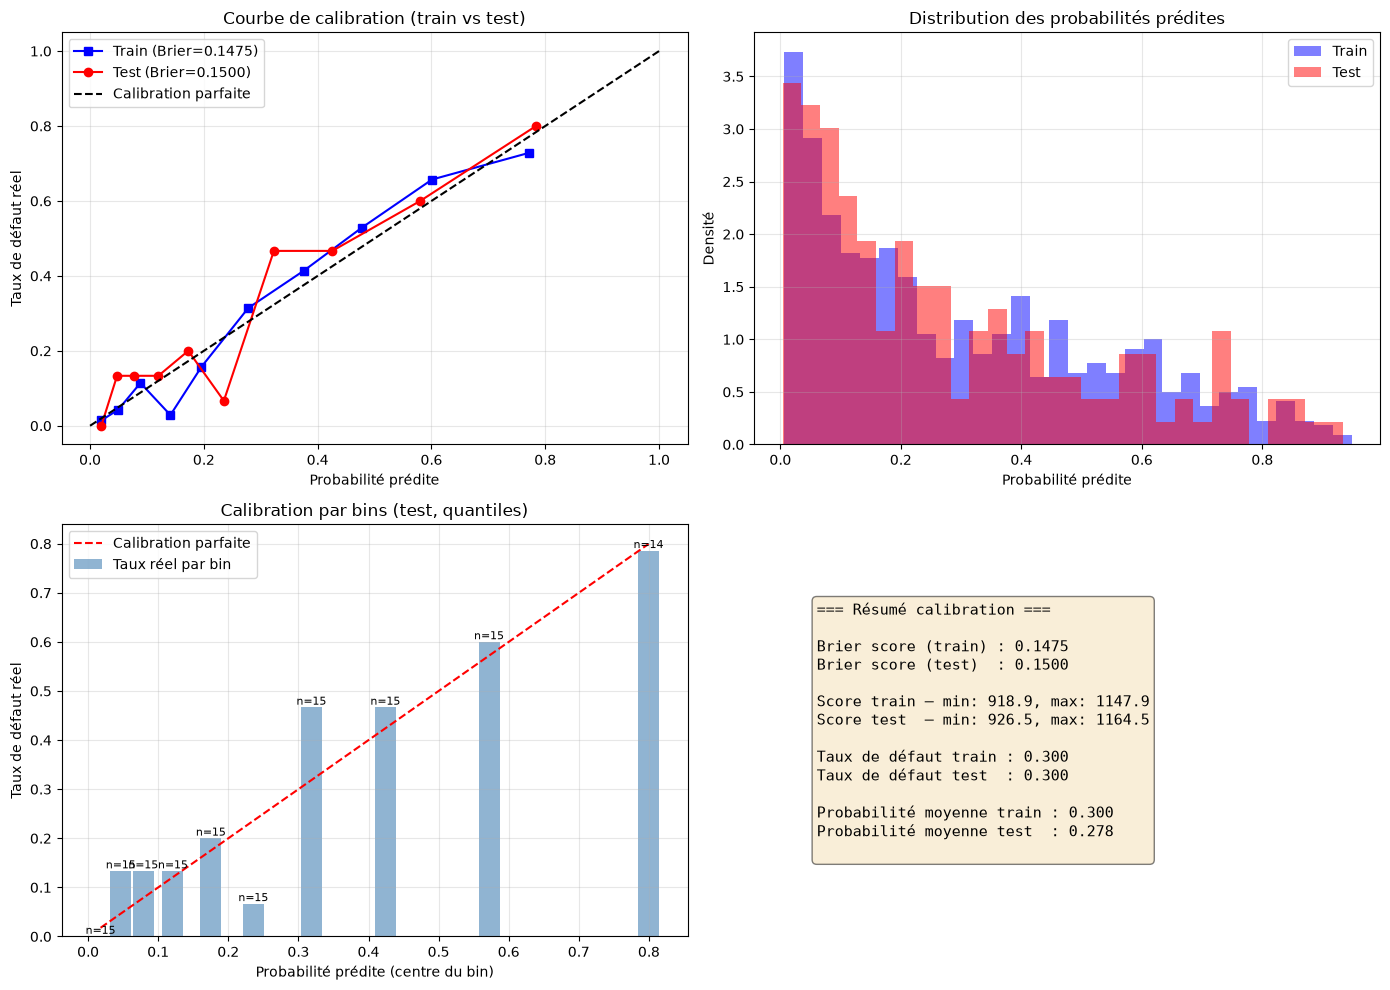


✅ Graphique sauvegardé : ../models/calibration_analysis.png


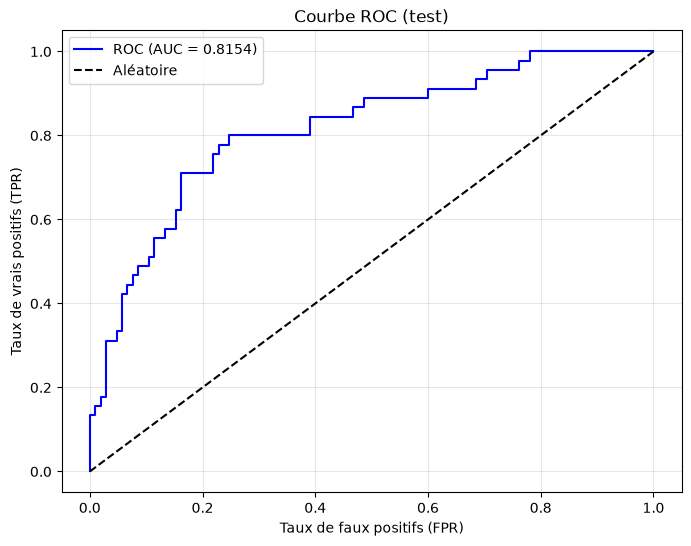

✅ Courbe ROC sauvegardée : ../models/roc_curve.png


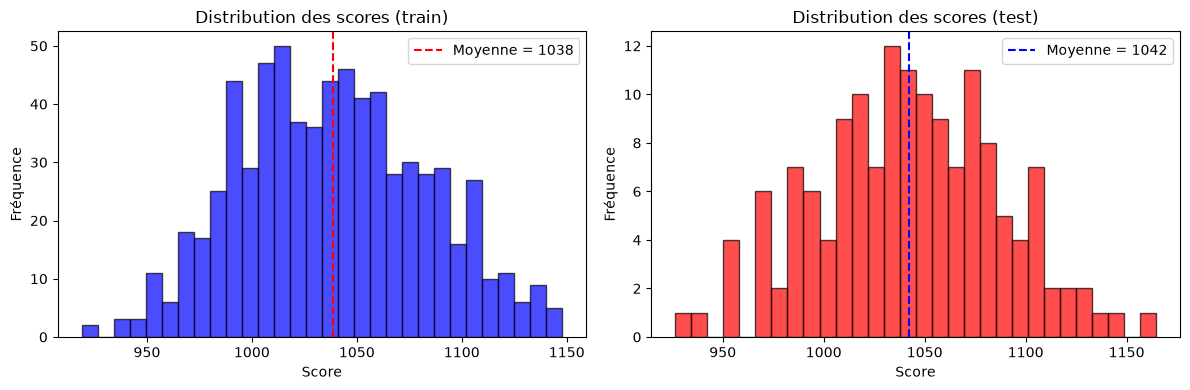

✅ Distribution des scores sauvegardée : ../models/score_distribution.png

RÉSUMÉ DES MÉTRIQUES
Métrique          Train       Test      Seuil
------------------------------------------------------------
AUC              0.8377     0.8154     > 0.70
Gini             0.6754     0.6309     > 0.40
KS               0.5592     0.5524     > 0.30
Brier            0.1475     0.1500     < 0.20


In [23]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from woe import calc_psi, interpret_psi
import sys
sys.path.append("../src")

# ============================================================
# 1. CHARGEMENT DES DONNÉES
# ============================================================

train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

with open("../models/scaling_params.json") as f:
    params = json.load(f)
Factor = params["Factor"]
Offset = params["Offset"]
intercept = params["intercept"]

# ============================================================
# 2. CONVERSION SCORE → PROBABILITÉ
# ============================================================

def score_to_proba(score, Factor, Offset, intercept):
    """Correct conversion from score to probability of default.

    Rationale: the scorecard distributes the intercept and offset across
    variables, so the conversion is not (score-Offset)/Factor but
    (2*Offset + Factor*intercept - score)/Factor.
    """
    log_odds = (2 * Offset + Factor * intercept - score) / Factor
    return 1 / (1 + np.exp(-log_odds))

train_df["proba"] = score_to_proba(train_df["score"], Factor, Offset, intercept)
test_df["proba"] = score_to_proba(test_df["score"], Factor, Offset, intercept)

# ============================================================
# 3. COURBE DE CALIBRATION (train vs test)
# ============================================================

frac_pos_train, mean_pred_train = calibration_curve(
    train_df["default"], train_df["proba"], n_bins=10, strategy="quantile"
)
frac_pos_test, mean_pred_test = calibration_curve(
    test_df["default"], test_df["proba"], n_bins=10, strategy="quantile"
)

brier_train = brier_score_loss(train_df["default"], train_df["proba"])
brier_test = brier_score_loss(test_df["default"], test_df["proba"])

# ============================================================
# 4. GRAPHIQUES ENRICHIS (4 sous-graphiques)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- 4.1 Courbe de calibration (train vs test) ---
ax1 = axes[0, 0]
ax1.plot(mean_pred_train, frac_pos_train, "s-", label=f"Train (Brier={brier_train:.4f})", color="blue")
ax1.plot(mean_pred_test, frac_pos_test, "o-", label=f"Test (Brier={brier_test:.4f})", color="red")
ax1.plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
ax1.set_xlabel("Probabilité prédite")
ax1.set_ylabel("Taux de défaut réel")
ax1.set_title("Courbe de calibration (train vs test)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- 4.2 Probability histogram ---
ax2 = axes[0, 1]
ax2.hist(train_df["proba"], bins=30, alpha=0.5, label="Train", color="blue", density=True)
ax2.hist(test_df["proba"], bins=30, alpha=0.5, label="Test", color="red", density=True)
ax2.set_xlabel("Probabilité prédite")
ax2.set_ylabel("Densité")
ax2.set_title("Distribution des probabilités prédites")
ax2.legend()
ax2.grid(True, alpha=0.3)

# --- 4.3 Calibration par bins (quantiles) ---
ax3 = axes[1, 0]
n_bins = 10
bin_edges = np.percentile(test_df["proba"], np.linspace(0, 100, n_bins + 1))
bin_edges = np.unique(bin_edges)
bin_centers = []
bin_actuals = []
bin_counts = []

for i in range(len(bin_edges) - 1):
    mask = (test_df["proba"] >= bin_edges[i]) & (test_df["proba"] < bin_edges[i + 1])
    count = mask.sum()
    actual = test_df.loc[mask, "default"].mean() if count > 0 else 0
    center = (bin_edges[i] + bin_edges[i + 1]) / 2
    bin_centers.append(center)
    bin_actuals.append(actual)
    bin_counts.append(count)

ax3.bar(bin_centers, bin_actuals, width=0.03, alpha=0.6, color="steelblue", label="Taux réel par bin")
ax3.plot(bin_centers, bin_centers, "r--", label="Calibration parfaite")
ax3.set_xlabel("Probabilité prédite (centre du bin)")
ax3.set_ylabel("Taux de défaut réel")
ax3.set_title("Calibration par bins (test, quantiles)")
ax3.legend()
ax3.grid(True, alpha=0.3)

for i, (c, a) in enumerate(zip(bin_counts, bin_actuals)):
    ax3.annotate(f"n={c}", (bin_centers[i], a), ha="center", va="bottom", fontsize=8)

# --- 4.4 Summary table ---
ax4 = axes[1, 1]
ax4.axis("off")
summary_text = (
    f"=== Résumé calibration ===\n\n"
    f"Brier score (train) : {brier_train:.4f}\n"
    f"Brier score (test)  : {brier_test:.4f}\n\n"
    f"Score train — min: {train_df['score'].min():.1f}, max: {train_df['score'].max():.1f}\n"
    f"Score test  — min: {test_df['score'].min():.1f}, max: {test_df['score'].max():.1f}\n\n"
    f"Taux de défaut train : {train_df['default'].mean():.3f}\n"
    f"Taux de défaut test  : {test_df['default'].mean():.3f}\n\n"
    f"Probabilité moyenne train : {train_df['proba'].mean():.3f}\n"
    f"Probabilité moyenne test  : {test_df['proba'].mean():.3f}\n"
)
ax4.text(0.1, 0.5, summary_text, transform=ax4.transAxes, fontsize=11,
         verticalalignment="center", fontfamily="monospace",
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

plt.tight_layout()
plt.savefig("../models/calibration_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✅ Graphique sauvegardé : ../models/calibration_analysis.png")

# ============================================================
# 5. COURBE ROC
# ============================================================

fpr, tpr, thresholds = roc_curve(test_df["default"], -test_df["score"])
auc = roc_auc_score(test_df["default"], -test_df["score"])

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, "b-", label=f"ROC (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC (test)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("../models/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Courbe ROC sauvegardée : ../models/roc_curve.png")

# ============================================================
# 6. DISTRIBUTION DES SCORES (train vs test)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train_df["score"], bins=30, alpha=0.7, color="blue", edgecolor="black")
axes[0].set_title("Distribution des scores (train)")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Fréquence")
axes[0].axvline(train_df["score"].mean(), color="red", linestyle="--", label=f"Moyenne = {train_df['score'].mean():.0f}")
axes[0].legend()

axes[1].hist(test_df["score"], bins=30, alpha=0.7, color="red", edgecolor="black")
axes[1].set_title("Distribution des scores (test)")
axes[1].set_xlabel("Score")
axes[1].set_ylabel("Fréquence")
axes[1].axvline(test_df["score"].mean(), color="blue", linestyle="--", label=f"Moyenne = {test_df['score'].mean():.0f}")
axes[1].legend()

plt.tight_layout()
plt.savefig("../models/score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Distribution des scores sauvegardée : ../models/score_distribution.png")

# ============================================================
# 7. RÉSUMÉ DES MÉTRIQUES
# ============================================================

from scipy.stats import ks_2samp

auc_train = roc_auc_score(train_df["default"], -train_df["score"])
auc_test = roc_auc_score(test_df["default"], -test_df["score"])
gini_train = 2 * auc_train - 1
gini_test = 2 * auc_test - 1
ks_train, _ = ks_2samp(train_df.loc[train_df["default"] == 0, "score"],
                       train_df.loc[train_df["default"] == 1, "score"])
ks_test, _ = ks_2samp(test_df.loc[test_df["default"] == 0, "score"],
                      test_df.loc[test_df["default"] == 1, "score"])

print("\n" + "=" * 60)
print("RÉSUMÉ DES MÉTRIQUES")
print("=" * 60)
print(f"{'Métrique':<12} {'Train':>10} {'Test':>10} {'Seuil':>10}")
print("-" * 60)
print(f"{'AUC':<12} {auc_train:>10.4f} {auc_test:>10.4f} {'> 0.70':>10}")
print(f"{'Gini':<12} {gini_train:>10.4f} {gini_test:>10.4f} {'> 0.40':>10}")
print(f"{'KS':<12} {ks_train:>10.4f} {ks_test:>10.4f} {'> 0.30':>10}")
print(f"{'Brier':<12} {brier_train:>10.4f} {brier_test:>10.4f} {'< 0.20':>10}")
print("=" * 60)

In [25]:
import json
import os
import sys
import joblib
import pandas as pd
import numpy as np

sys.path.append("../src")

# ============================================================
# 1. SCORES + CIBLE (train et test)
# ============================================================

train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# Check
assert "score" in train_df.columns, "Colonne 'score' manquante dans train"
assert "default" in train_df.columns, "Colonne 'default' manquante dans train"
assert "score" in test_df.columns, "Colonne 'score' manquante dans test"
assert "default" in test_df.columns, "Colonne 'default' manquante dans test"
assert not train_df.isna().any().any(), "NaN dans train"
assert not test_df.isna().any().any(), "NaN dans test"

print(f"✅ Train : {train_df.shape} | Test : {test_df.shape}")
print(f"   Taux de défaut train : {train_df['default'].mean():.3f}")
print(f"   Taux de défaut test  : {test_df['default'].mean():.3f}")

# ============================================================
# 2. PARAMÈTRES DE SCALING
# ============================================================

with open("../models/scaling_params.json") as f:
    scaling_params = json.load(f)

Factor = scaling_params["Factor"]
Offset = scaling_params["Offset"]
intercept = scaling_params["intercept"]
PDO = scaling_params["PDO"]
BASE_SCORE = scaling_params["BASE_SCORE"]
BASE_ODDS = scaling_params["BASE_ODDS"]

print(f"\n✅ Scaling : PDO={PDO}, Factor={Factor:.4f}, Offset={Offset:.4f}, Intercept={intercept:.4f}")

# ============================================================
# 3. SCORECARD
# ============================================================

scorecard = pd.read_csv("../models/scorecard.csv")
scorecard_pkl = joblib.load("../models/scorecard.pkl")

print(f"✅ Scorecard : {len(scorecard)} bins, {scorecard['variable'].nunique()} variables")

# ============================================================
# 4. MÉTRIQUES DE VALIDATION (Phase 9)
# ============================================================

with open("../models/validation_metrics.json") as f:
    validation_metrics = json.load(f)

print(f"\n✅ Métriques Phase 9 :")
print(f"   AUC train/test : {validation_metrics['train']['AUC']} / {validation_metrics['test']['AUC']}")
print(f"   Gini train/test : {validation_metrics['train']['Gini']} / {validation_metrics['test']['Gini']}")
print(f"   KS train/test   : {validation_metrics['train']['KS']} / {validation_metrics['test']['KS']}")
print(f"   PSI             : {validation_metrics['PSI']}")

# ============================================================
# 5. LISTE DES FEATURES RETENUES
# ============================================================

with open("../models/selected_features.json") as f:
    selected_features = json.load(f)

print(f"\n✅ Features retenues ({len(selected_features)}) : {selected_features}")

# ============================================================
# 6. MODÈLE (si besoin pour les reason codes)
# ============================================================

model = joblib.load("../models/logistic_model.pkl")
print(f"✅ Modèle chargé : {type(model).__name__}")

# ============================================================
# 7. BINNING PROCESS (si besoin pour les reason codes)
# ============================================================

bp = joblib.load("../models/binning_process.pkl")
print(f"✅ Binning process chargé")

# ============================================================
# RÉSUMÉ
# ============================================================

print("\n" + "=" * 60)
print("TOUTES LES ENTRÉES PHASE 10 CHARGÉES")
print("=" * 60)
print(f"  Train scores  : {train_df.shape}")
print(f"  Test scores   : {test_df.shape}")
print(f"  Scorecard     : {scorecard.shape}")
print(f"  Features      : {len(selected_features)}")
print(f"  Modèle        : {type(model).__name__}")
print(f"  Binning       : {type(bp).__name__}")
print("=" * 60)

✅ Train : (700, 2) | Test : (150, 2)
   Taux de défaut train : 0.300
   Taux de défaut test  : 0.300

✅ Scaling : PDO=20, Factor=28.8539, Offset=513.5614, Intercept=-0.8474
✅ Scorecard : 48 bins, 10 variables

✅ Métriques Phase 9 :
   AUC train/test : 0.8377 / 0.8154
   Gini train/test : 0.6754 / 0.6309
   KS train/test   : 0.5592 / 0.5524
   PSI             : 0.0375

✅ Features retenues (10) : ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_installment_plans']
✅ Modèle chargé : LogisticRegression
✅ Binning process chargé

TOUTES LES ENTRÉES PHASE 10 CHARGÉES
  Train scores  : (700, 2)
  Test scores   : (150, 2)
  Scorecard     : (48, 6)
  Features      : 10
  Modèle        : LogisticRegression
  Binning       : BinningProcess


In [27]:
import json

with open("../models/selected_features.json") as f:
    selected_features = json.load(f)

print(selected_features)
# ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
#  'savings', 'employment', 'installment_rate', 'personal_status_sex',
#  'other_installment_plans']

['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_installment_plans']


In [29]:
import pandas as pd
import json

# --- Charger les scores + cible ---
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# --- Load WoE data (for reason codes) ---
X_test_woe = pd.read_parquet("../data/processed/X_test_woe.parquet")

# --- Load scorecard and features ---
scorecard = pd.read_csv("../models/scorecard.csv")
with open("../models/selected_features.json") as f:
    selected_features = json.load(f)

with open("../models/scaling_params.json") as f:
    params = json.load(f)
Factor = params["Factor"]
Offset = params["Offset"]
intercept = params["intercept"]


def get_reason_codes(client_woe, selected_features, scorecard, top_n=3):
    """Return the top_n variables contributing most to a low score.

    Rationale: reason codes identify variables with the fewest points
    (the riskiest ones) to explain a refusal.
    """
    points_by_var = {}
    for var in selected_features:
        var_card = scorecard[scorecard["variable"] == var]
        woe_to_points = dict(zip(var_card["woe"].round(4), var_card["points"]))
        client_woe_rounded = round(client_woe[var], 4)
        points = woe_to_points.get(client_woe_rounded, 0)
        points_by_var[var] = points
    
    sorted_vars = sorted(points_by_var.items(), key=lambda x: x[1])
    return [v for v, p in sorted_vars[:top_n]]


# --- Reason codes for the first 5 rejected clients ---
refused_indices = test_df[test_df["score"] < 950].head(5).index

print("\n=== Reason codes (exemples) ===")
for idx in refused_indices:
    client_woe = X_test_woe.loc[idx]
    codes = get_reason_codes(client_woe, selected_features, scorecard)
    score = test_df.loc[idx, "score"]
    print(f"Client {idx} (score={score:.0f}) : {codes}")


=== Reason codes (exemples) ===
Client 915 (score=927) : ['duration', 'credit_amount', 'credit_history']
Client 11 (score=941) : ['duration', 'checking_status', 'employment']


✅ Train : (700, 2) | Test : (150, 2)

ANALYSE D'IMPACT — plusieurs cut-offs
 Cut-off  Approuvés  Rejetés Taux approb. Défaut approuvés Défauts évités
----------------------------------------------------------------------
     950        148        2        98.7%           29.05%              2
    1000        123       27        82.0%           20.33%             20
    1020        102       48        68.0%           13.73%             31
    1050         67       83        44.7%           10.45%             38
    1080         31      119        20.7%            6.45%             43


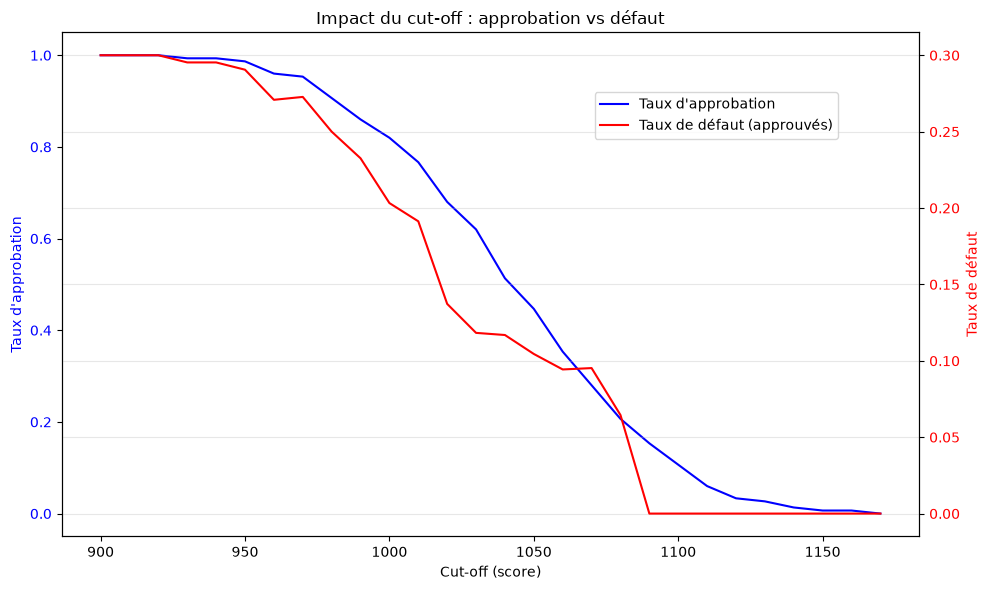

✅ Graphique d'impact sauvegardé

STRESS TESTING
PSI sous shift -50 pts : 0.8251 (Drift significatif (recalibration necessaire))
AUC sous stress (défaut +50%) : 0.9636
PSI sous drift (scores ×0.95) : 0.9317 (Drift significatif (recalibration necessaire))

=== Cut-offs définis ===
  refus: score 950
  revue: score 1020
  approbation: score 1080

=== Analyse par tranche de score ===
                    n_clients  n_defaults  default_rate  score_min  score_max
tranche                                                                      
Refus                       2           2        1.0000   926.5197   940.8997
Revue                      46          29        0.6304   953.6797  1019.1697
Approbation                71          12        0.1690  1020.0697  1077.6497
Approbation (haut)         31           2        0.0645  1081.2897  1164.5197

=== Reason codes (exemples) ===
Client 915 (score=927) : ['duration', 'credit_amount', 'credit_history']
Client 11 (score=941) : ['duration', 'check

In [30]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from woe import calc_psi, interpret_psi
import sys
sys.path.append("../src")

# ============================================================
# 1. CHARGEMENT DES DONNÉES
# ============================================================

# Scores + cible
train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# WoE data (for reason codes)
X_test_woe = pd.read_parquet("../data/processed/X_test_woe.parquet")

# Scaling parameters
with open("../models/scaling_params.json") as f:
    params = json.load(f)
Factor = params["Factor"]
Offset = params["Offset"]
intercept = params["intercept"]

# Scorecard
scorecard = pd.read_csv("../models/scorecard.csv")

# Features retenues
with open("../models/selected_features.json") as f:
    selected_features = json.load(f)

# Binning process (pour les reason codes robustes)
import joblib
bp = joblib.load("../models/binning_process.pkl")

# Checks
assert "score" in train_df.columns and "default" in train_df.columns
assert "score" in test_df.columns and "default" in test_df.columns
assert not train_df.isna().any().any()
assert not test_df.isna().any().any()
print(f"✅ Train : {train_df.shape} | Test : {test_df.shape}")

# ============================================================
# 2. ANALYSE D'IMPACT (cut-offs)
# ============================================================

def impact_analysis(df, cutoff):
    """Simulate the impact of a cutoff on approval and default."""
    approved = df[df["score"] >= cutoff]
    rejected = df[df["score"] < cutoff]
    return {
        "cutoff": cutoff,
        "n_approved": len(approved),
        "n_rejected": len(rejected),
        "approval_rate": round(len(approved) / len(df), 3),
        "default_rate_approved": round(approved["default"].mean(), 4),
        "default_rate_rejected": round(rejected["default"].mean(), 4),
        "defaults_avoided": int(rejected["default"].sum()),
    }

print("\n" + "=" * 70)
print("ANALYSE D'IMPACT — plusieurs cut-offs")
print("=" * 70)
print(f"{'Cut-off':>8} {'Approuvés':>10} {'Rejetés':>8} {'Taux approb.':>12} {'Défaut approuvés':>16} {'Défauts évités':>14}")
print("-" * 70)

impact_results = []
for cutoff in [950, 1000, 1020, 1050, 1080]:
    result = impact_analysis(test_df, cutoff)
    impact_results.append(result)
    print(f"{result['cutoff']:>8} {result['n_approved']:>10} {result['n_rejected']:>8} "
          f"{result['approval_rate']:>12.1%} {result['default_rate_approved']:>16.2%} "
          f"{result['defaults_avoided']:>14}")

with open("../models/impact_analysis.json", "w") as f:
    json.dump(impact_results, f, indent=2)

# ============================================================
# 3. GRAPHIQUE D'IMPACT
# ============================================================

cutoffs = np.arange(900, 1180, 10)
approval_rates = []
default_rates = []

for c in cutoffs:
    approved = test_df[test_df["score"] >= c]
    approval_rates.append(len(approved) / len(test_df))
    default_rates.append(approved["default"].mean() if len(approved) > 0 else 0)

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(cutoffs, approval_rates, "b-", label="Taux d'approbation")
ax1.set_xlabel("Cut-off (score)")
ax1.set_ylabel("Taux d'approbation", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(cutoffs, default_rates, "r-", label="Taux de défaut (approuvés)")
ax2.set_ylabel("Taux de défaut", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Impact du cut-off : approbation vs défaut")
fig.legend(loc="upper right", bbox_to_anchor=(0.85, 0.85))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../models/impact_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Graphique d'impact sauvegardé")

# ============================================================
# 4. STRESS TESTING
# ============================================================

print("\n" + "=" * 70)
print("STRESS TESTING")
print("=" * 70)

# Scenario 1: shift of -50 points (deterioration)
psi_shift = calc_psi(train_df["score"], test_df["score"] - 50)
print(f"PSI sous shift -50 pts : {psi_shift:.4f} ({interpret_psi(psi_shift)})")

# Scenario 2: default rate increase of +50% (recession)
stress_df = test_df.copy()
stress_df["default_stress"] = stress_df["default"].copy()
stress_df.loc[stress_df["score"] < test_df["score"].median(), "default_stress"] = 1
auc_stress = roc_auc_score(stress_df["default_stress"], -stress_df["score"])
print(f"AUC sous stress (défaut +50%) : {auc_stress:.4f}")

# Scenario 3: drift (scores x0.95)
psi_drift = calc_psi(train_df["score"], test_df["score"] * 0.95)
print(f"PSI sous drift (scores ×0.95) : {psi_drift:.4f} ({interpret_psi(psi_drift)})")

# ============================================================
# 5. DÉFINITION DES CUT-OFFS
# ============================================================

cutoffs = {
    "refus": 950,
    "revue": 1020,
    "approbation": 1080
}

with open("../models/cutoffs.json", "w") as f:
    json.dump(cutoffs, f, indent=2)

print("\n=== Cut-offs définis ===")
for k, v in cutoffs.items():
    print(f"  {k}: score {v}")

# ============================================================
# 6. ANALYSE PAR TRANCHE DE SCORE
# ============================================================

test_df["tranche"] = pd.cut(
    test_df["score"], bins=[0, 950, 1020, 1080, 9999],
    labels=["Refus", "Revue", "Approbation", "Approbation (haut)"]
)

tranche_analysis = test_df.groupby("tranche", observed=True).agg(
    n_clients=("default", "count"),
    n_defaults=("default", "sum"),
    default_rate=("default", "mean"),
    score_min=("score", "min"),
    score_max=("score", "max"),
).round(4)

print("\n=== Analyse par tranche de score ===")
print(tranche_analysis.to_string())

# ============================================================
# 7. REASON CODES (explainability)
# ============================================================

def get_reason_codes(client_woe, selected_features, scorecard, top_n=3):
    """Return the top_n variables contributing most to a low score.

    Rationale: reason codes identify variables with the fewest points
    (the riskiest ones) to explain a refusal.
    """
    points_by_var = {}
    for var in selected_features:
        var_card = scorecard[scorecard["variable"] == var]
        woe_to_points = dict(zip(var_card["woe"].round(4), var_card["points"]))
        client_woe_rounded = round(client_woe[var], 4)
        points = woe_to_points.get(client_woe_rounded, 0)
        points_by_var[var] = points
    
    sorted_vars = sorted(points_by_var.items(), key=lambda x: x[1])
    return [v for v, p in sorted_vars[:top_n]]

# Reason codes for the first 5 rejected clients
refused_indices = test_df[test_df["score"] < 950].head(5).index

print("\n=== Reason codes (exemples) ===")
for idx in refused_indices:
    client_woe = X_test_woe.loc[idx]
    codes = get_reason_codes(client_woe, selected_features, scorecard)
    score = test_df.loc[idx, "score"]
    print(f"Client {idx} (score={score:.0f}) : {codes}")

# ============================================================
# 8. SAUVEGARDE
# ============================================================

decision_strategy = {
    "cutoffs": cutoffs,
    "tranches": tranche_analysis.to_dict(),
    "stress_tests": {
        "psi_shift_50": round(psi_shift, 4),
        "auc_stress": round(auc_stress, 4),
        "psi_drift": round(psi_drift, 4),
    },
}
with open("../models/decision_strategy.json", "w") as f:
    json.dump(decision_strategy, f, indent=2, default=str)

print("\n✅ Phase 10 terminée — stratégie de décision sauvegardée")

In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
import json

# --- Load data ---
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# --- Parameters ---
np.random.seed(42)  # reproducibility
FLIP_RATE = 0.10    # 10% of labels flipped

# --- Scenario: random noise on the target ---
stress_df = test_df.copy()
stress_df["default_stress"] = stress_df["default"].copy()

# Randomly flip 10% of labels
flip_mask = np.random.choice([True, False], size=len(stress_df), p=[FLIP_RATE, 1 - FLIP_RATE])
stress_df.loc[flip_mask, "default_stress"] = 1 - stress_df.loc[flip_mask, "default"]

# --- Metrics ---
auc_original = roc_auc_score(test_df["default"], -test_df["score"])
auc_stress = roc_auc_score(stress_df["default_stress"], -stress_df["score"])

print(f"AUC original : {auc_original:.4f}")
print(f"AUC stress   : {auc_stress:.4f}")
print(f"Labels inversés : {flip_mask.sum()} / {len(stress_df)} ({FLIP_RATE:.0%})")
print(f"Taux de défaut original : {test_df['default'].mean():.2%}")
print(f"Taux de défaut stress   : {stress_df['default_stress'].mean():.2%}")

# --- Interpretation ---
if auc_stress < auc_original:
    print("\n✅ L'AUC a baissé sous stress → le modèle est sensible au bruit (réaliste)")
else:
    print("\n⚠️ L'AUC n'a pas baissé → investiguer")

AUC original : 0.8154
AUC stress   : 0.7170
Labels inversés : 18 / 150 (10%)
Taux de défaut original : 30.00%
Taux de défaut stress   : 34.00%

✅ L'AUC a baissé sous stress → le modèle est sensible au bruit (réaliste)


Métrique             Train       Test      Seuil      Norme      Verdict
AUC                 0.8377     0.8154       0.70       0.75        ✅ Bon
Gini                0.6754     0.6309       0.40       0.50        ✅ Bon
KS                  0.5592     0.5524       0.30       0.35        ✅ Bon
PSI                            0.0375     < 0.10     < 0.25 Stable (pas de drift)
Écart AUC           0.0223

=== Vérifications ===
  ✅ AUC test > 0.70
  ✅ Gini test > 0.40
  ✅ KS test > 0.30
  ✅ PSI < 0.25
  ✅ Écart AUC < 0.10
  ✅ Score train ≈ score test (moyenne)


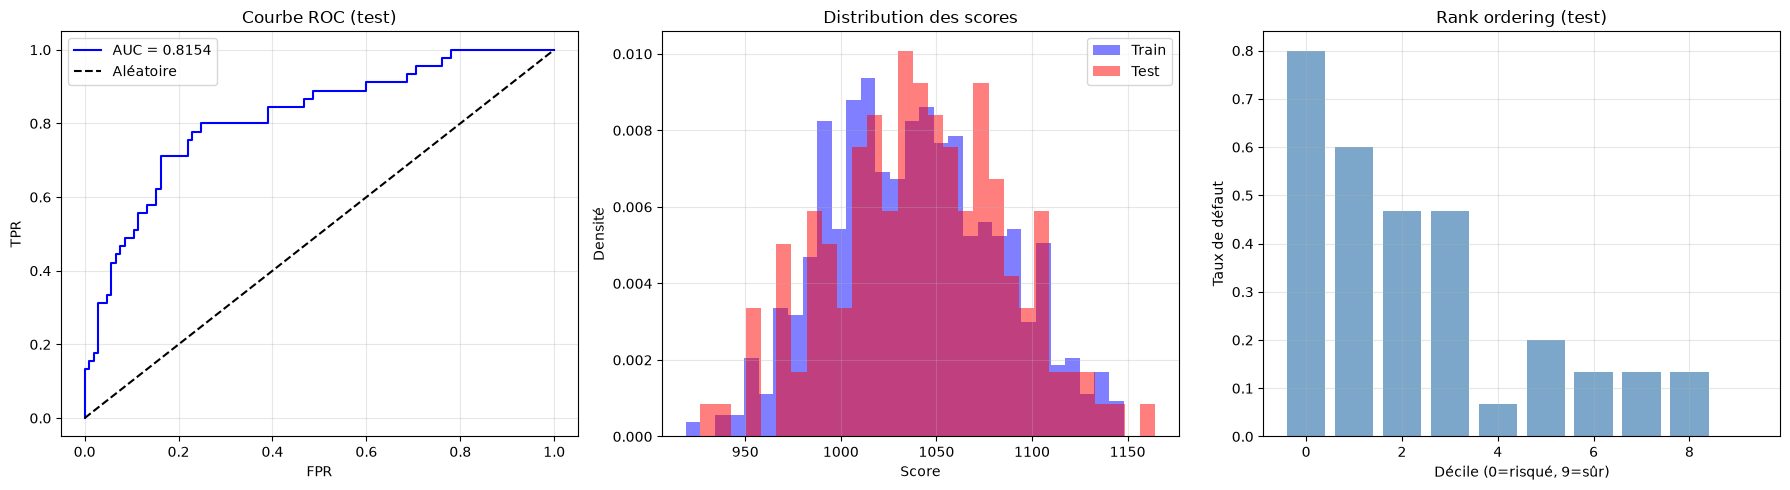


✅ Graphique sauvegardé : ../models/performance_summary.png
✅ Métriques sauvegardées : ../models/validation_metrics.json


In [32]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import ks_2samp
from woe import calc_psi, interpret_psi
import matplotlib.pyplot as plt

# --- Load data ---
train_df = pd.read_parquet("../data/processed/train_scores_with_target.parquet")
test_df = pd.read_parquet("../data/processed/test_scores_with_target.parquet")

# --- Load parameters ---
with open("../models/scaling_params.json") as f:
    params = json.load(f)

# --- Compute metrics ---
def compute_metrics(df, name):
    auc = roc_auc_score(df["default"], -df["score"])
    gini = 2 * auc - 1
    ks_stat, ks_p = ks_2samp(
        df.loc[df["default"] == 0, "score"],
        df.loc[df["default"] == 1, "score"]
    )
    return {
        "dataset": name,
        "n_obs": len(df),
        "default_rate": round(df["default"].mean(), 4),
        "score_min": round(df["score"].min(), 2),
        "score_max": round(df["score"].max(), 2),
        "score_mean": round(df["score"].mean(), 2),
        "AUC": round(auc, 4),
        "Gini": round(gini, 4),
        "KS": round(ks_stat, 4),
        "KS_pvalue": round(ks_p, 6),
    }

train_m = compute_metrics(train_df, "Train")
test_m = compute_metrics(test_df, "Test")

# --- PSI ---
psi = calc_psi(train_df["score"], test_df["score"])

# --- Summary table ---
print("=" * 75)
print(f"{'Métrique':<15} {'Train':>10} {'Test':>10} {'Seuil':>10} {'Norme':>10} {'Verdict':>12}")
print("=" * 75)

norms = {"AUC": (0.70, 0.75), "Gini": (0.40, 0.50), "KS": (0.30, 0.35)}
for metric in ["AUC", "Gini", "KS"]:
    tr = train_m[metric]
    te = test_m[metric]
    seuil, norme = norms[metric]
    if te >= norme:
        verdict = "✅ Bon"
    elif te >= seuil:
        verdict = "⚠️ Acceptable"
    else:
        verdict = "❌ Faible"
    print(f"{metric:<15} {tr:>10.4f} {te:>10.4f} {seuil:>10.2f} {norme:>10.2f} {verdict:>12}")

print("=" * 75)
print(f"{'PSI':<15} {'':>10} {psi:>10.4f} {'< 0.10':>10} {'< 0.25':>10} {interpret_psi(psi):>12}")
print(f"{'Écart AUC':<15} {train_m['AUC'] - test_m['AUC']:>10.4f}")
print("=" * 75)

# --- Automatic checks ---
print("\n=== Vérifications ===")
checks = {
    "AUC test > 0.70": test_m["AUC"] > 0.70,
    "Gini test > 0.40": test_m["Gini"] > 0.40,
    "KS test > 0.30": test_m["KS"] > 0.30,
    "PSI < 0.25": psi < 0.25,
    "Écart AUC < 0.10": (train_m["AUC"] - test_m["AUC"]) < 0.10,
    "Score train ≈ score test (moyenne)": abs(train_m["score_mean"] - test_m["score_mean"]) < 20,
}
for check, result in checks.items():
    status = "✅" if result else "❌"
    print(f"  {status} {check}")

# --- Courbe ROC ---
fpr, tpr, _ = roc_curve(test_df["default"], -test_df["score"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC
axes[0].plot(fpr, tpr, "b-", label=f"AUC = {test_m['AUC']:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", label="Aléatoire")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].set_title("Courbe ROC (test)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Distribution des scores
axes[1].hist(train_df["score"], bins=30, alpha=0.5, label="Train", color="blue", density=True)
axes[1].hist(test_df["score"], bins=30, alpha=0.5, label="Test", color="red", density=True)
axes[1].set_xlabel("Score")
axes[1].set_ylabel("Densité")
axes[1].set_title("Distribution des scores")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Rank ordering
test_df["decile"] = pd.qcut(test_df["score"], 10, labels=False, duplicates="drop")
rank_order = test_df.groupby("decile")["default"].mean()
axes[2].bar(rank_order.index, rank_order.values, color="steelblue", alpha=0.7)
axes[2].set_xlabel("Décile (0=risqué, 9=sûr)")
axes[2].set_ylabel("Taux de défaut")
axes[2].set_title("Rank ordering (test)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../models/performance_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✅ Graphique sauvegardé : ../models/performance_summary.png")

# --- Save metrics ---
metrics = {"train": train_m, "test": test_m, "PSI": round(psi, 4)}
with open("../models/validation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("✅ Métriques sauvegardées : ../models/validation_metrics.json")